In [1]:
import os
import numpy as np
import librosa
import h5py
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
import pickle
from joblib import Parallel, delayed
import pandas as pd
import glob

np.random.seed(907)

In [2]:
import numpy as np
import pandas as pd
import librosa

def extract_features(y, sr, window_size=0.5, fixed_windows=60):
    # This function segments the audio, computes various features per window,
    # and returns a fixed number of windows by padding or truncating.
    # of course this is too much features and i won't be using them all 
    #i just compute all of it so if i need anything i don't need to compute again

    def sanitize_audio_buffer(y_segment):
        # Replace invalid values in audio buffer.
        return np.nan_to_num(y_segment, nan=0.0, posinf=1.0, neginf=-1.0)

    def compute_all_features(y_window, sr):
        # Compute multiple time-domain and frequency-domain audio features.
        features = {}
        try:
            cqt = librosa.cqt(y=y_window, sr=sr, bins_per_octave=24, n_bins=96)
            cqt_mag = np.abs(cqt)
            cqt_mean = np.mean(cqt_mag, axis=1)
            for i, val in enumerate(cqt_mean):
                features[f"cqt_{i}"] = val
        except Exception as e:
            print(f"CQT Extraction Error: {e}")
            for i in range(96):
                features[f"cqt_{i}"] = 0.0
        try:
            chroma_cqt = librosa.feature.chroma_cqt(C=cqt, sr=sr, bins_per_octave=24)
            chroma_cqt_mean = np.mean(chroma_cqt, axis=1)
            for i, val in enumerate(chroma_cqt_mean):
                features[f"chroma_cqt_{i}"] = val
        except Exception as e:
            print(f"Chroma CQT Extraction Error: {e}")
            for i in range(12):
                features[f"chroma_cqt_{i}"] = 0.0
        try:
            pitches, magnitudes = librosa.piptrack(y=y_window, sr=sr)
            pitch_contours_full = np.mean(pitches, axis=1)
            start_idx = 14
            end_idx = 372
            total_bins = pitch_contours_full.shape[0]
            if end_idx > total_bins:
                end_idx = total_bins
            pitch_contours = pitch_contours_full[start_idx:end_idx]
            pitch_mean = np.mean(pitch_contours) if len(pitch_contours) > 0 else 0.0
            for i, val in enumerate(pitch_contours):
                features[f"pitch_contours_{i}"] = val
            features["pitch_mean"] = pitch_mean
        except Exception as e:
            print(f"Pitch Contours Extraction Error: {e}")
            for i in range(358):
                features[f"pitch_contours_{i}"] = 0.0
            features["pitch_mean"] = 0.0
        try:
            spectral_contrast = librosa.feature.spectral_contrast(y=y_window, sr=sr)
            spectral_contrast_mean = np.mean(spectral_contrast, axis=1)
            for i, val in enumerate(spectral_contrast_mean):
                features[f"spectral_contrast_{i}"] = val
        except Exception as e:
            print(f"Spectral Contrast Extraction Error: {e}")
            for i in range(7):
                features[f"spectral_contrast_{i}"] = 0.0
        try:
            harmonic = librosa.effects.harmonic(y=y_window)
            tonnetz = librosa.feature.tonnetz(y=harmonic, sr=sr)
            tonnetz_mean = np.mean(tonnetz, axis=1)
            for i, val in enumerate(tonnetz_mean):
                features[f"tonnetz_{i}"] = val
        except Exception as e:
            print(f"Tonnetz Extraction Error: {e}")
            for i in range(6):
                features[f"tonnetz_{i}"] = 0.0
        try:
            rms = librosa.feature.rms(y=y_window)
            features["RMS_mean"] = np.mean(rms)
        except Exception as e:
            print(f"RMS Extraction Error: {e}")
            features["RMS_mean"] = 0.0
        try:
            spectral_centroid = librosa.feature.spectral_centroid(y=y_window, sr=sr)
            features["spectral_centroid"] = np.mean(spectral_centroid)
        except Exception as e:
            print(f"Spectral Centroid Extraction Error: {e}")
            features["spectral_centroid"] = 0.0
        try:
            spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y_window, sr=sr)
            features["spectral_bandwidth"] = np.mean(spectral_bandwidth)
        except Exception as e:
            print(f"Spectral Bandwidth Extraction Error: {e}")
            features["spectral_bandwidth"] = 0.0
        try:
            zcr = librosa.feature.zero_crossing_rate(y=y_window)
            features["zero_crossing_rate"] = np.mean(zcr)
        except Exception as e:
            print(f"Zero-Crossing Rate Extraction Error: {e}")
            features["zero_crossing_rate"] = 0.0
        try:
            chroma_stft = librosa.feature.chroma_stft(y=y_window, sr=sr)
            chroma_stft_mean = np.mean(chroma_stft, axis=1)
            for i, val in enumerate(chroma_stft_mean):
                features[f"chroma_stft_{i}"] = val
        except Exception as e:
            print(f"Chroma STFT Extraction Error: {e}")
            for i in range(12):
                features[f"chroma_stft_{i}"] = 0.0
        try:
            mel_spec = librosa.feature.melspectrogram(y=y_window, sr=sr, n_mels=128)
            mel_spec_mean = np.mean(mel_spec, axis=1)
            for i, val in enumerate(mel_spec_mean):
                features[f"mel_spectrogram_{i}"] = val
        except Exception as e:
            print(f"Mel-Spectrogram Extraction Error: {e}")
            for i in range(128):
                features[f"mel_spectrogram_{i}"] = 0.0
        try:
            S = np.abs(librosa.stft(y=y_window, n_fft=2048, hop_length=512))
            flux = np.sum(np.diff(S, axis=1)**2, axis=0)
            features["spectral_flux"] = np.mean(flux) if len(flux) > 0 else 0.0
        except Exception as e:
            print(f"Spectral Flux Extraction Error: {e}")
            features["spectral_flux"] = 0.0
        try:
            tempogram = librosa.feature.tempogram(y=y_window, sr=sr)
            autocorr = tempogram.flatten()
            if len(autocorr) < 384:
                autocorr_padded = np.pad(autocorr, (0, 384 - len(autocorr)), 'constant')
            else:
                autocorr_padded = autocorr[:384]
            for i, val in enumerate(autocorr_padded):
                features[f"autocorrelation_{i}"] = val
        except Exception as e:
            print(f"Autocorrelation Extraction Error: {e}")
            for i in range(384):
                features[f"autocorrelation_{i}"] = 0.0
        try:
            mfccs = librosa.feature.mfcc(y=y_window, sr=sr, n_mfcc=20)
            mfccs_mean = np.mean(mfccs, axis=1)
            for i, val in enumerate(mfccs_mean):
                features[f"mfcc_{i}"] = val
        except Exception as e:
            print(f"MFCC Extraction Error: {e}")
            for i in range(20):
                features[f"mfcc_{i}"] = 0.0
        try:
            mfccs_delta = librosa.feature.delta(mfccs, width=9, mode='interp')
            mfccs_delta_mean = np.mean(mfccs_delta, axis=1)
            for i, val in enumerate(mfccs_delta_mean):
                features[f"mfcc_delta_{i}"] = val
        except Exception as e:
            print(f"MFCC Delta Extraction Error: {e}")
            for i in range(20):
                features[f"mfcc_delta_{i}"] = 0.0
        return features

    samples_per_window = int(sr * window_size)
    total_samples = len(y)
    num_windows = int(np.ceil(total_samples / samples_per_window))
    feature_list = []
    for i in range(num_windows):
        start_sample = i * samples_per_window
        end_sample = start_sample + samples_per_window
        y_window = y[start_sample:end_sample]
        if len(y_window) < samples_per_window:
            padding = samples_per_window - len(y_window)
            y_window = np.pad(y_window, (0, padding), 'constant')
        y_window = sanitize_audio_buffer(y_window)
        features = compute_all_features(y_window, sr)
        features["window_number"] = i + 1
        features["start_time_sec"] = i * window_size
        features["end_time_sec"] = (i + 1) * window_size
        feature_list.append(features)
    features_df = pd.DataFrame(feature_list)
    current_windows = features_df.shape[0]
    if current_windows < fixed_windows:
        padding = fixed_windows - current_windows
        pad_features = np.zeros((padding, features_df.shape[1]))
        features_array = np.vstack([features_df.to_numpy(), pad_features])
    elif current_windows > fixed_windows:
        features_array = features_df.to_numpy()[:fixed_windows, :]
    else:
        features_array = features_df.to_numpy()
    return features_array


In [3]:
def augment_audio(y, sr):
    """
    Applies the final set of augmentations chosen by the experts.
      - Time Stretch: random in [0.8, 1.2]
      - Pitch Shift: random in [-1, +1]
      - White Noise: scale=0.05
      - Time Shift: circular shift in [1000, 2000]
      - Volume Scale: random in [0.25, 1.3]

    Returns a list of tuples (augmented_waveform, augmentation_type).
    """
    augmentations = []
    
    # Original
    augmentations.append((y, "original"))

    # Time Stretch
    rate = np.random.uniform(0.8, 1.2)
    stretched = librosa.effects.time_stretch(y=y, rate=rate)
    augmentations.append((stretched, f"time_stretch_{rate:.2f}"))

    # Pitch Shift
    n_steps = np.random.uniform(-1, 1) # i think it would be better if you used -0.5. 0.5
    pitch_shifted = librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)
    augmentations.append((pitch_shifted, f"pitch_shift_{n_steps:.2f}"))
    
    
    # White Noise
    noise = 0.05 * np.random.randn(len(y))
    with_noise = y + noise
    augmentations.append((with_noise, "white_noise"))
    
    
    # Time Shift: random integer in [1000, 2000]
    shift_amount = np.random.randint(1000, 2001)
    shifted = np.roll(y, shift_amount)
    augmentations.append((shifted, f"time_shift_{shift_amount}"))
    
    # Volume Scale
    volume_scale = np.random.uniform(0.25, 1.3)
    scaled = y * volume_scale
    augmentations.append((scaled, f"volume_scale_{volume_scale:.2f}"))
    
    return augmentations


In [4]:
def process_single_file(audio_path, maqam_label, sr, fixed_windows=60):
    """
    Processes a single audio file with augmentations.
    Returns a list of NumPy arrays with shape (fixed_windows, features).
    """
    y, _ = librosa.load(audio_path, sr=sr, mono=True)
    augmented_versions = augment_audio(y, sr)
    
    maquam_arrays = []
    for (aug_wave, aug_type) in augmented_versions:
        feats = extract_features_per_window(aug_wave, sr=sr)
        maquam_arrays.append(feats)
    
    return maquam_arrays


In [5]:
def process_maqam_dataset(input_root='music_data', 
                          sr=22050, 
                          output_dir='.', 
                          n_jobs=-1,
                          fixed_windows=60):
    import os
    import glob
    from tqdm import tqdm
    from joblib import Parallel, delayed
    import numpy as np
    import pandas as pd
    
    os.makedirs(output_dir, exist_ok=True)
    all_dataarrays = []
    all_labels = []
    
    maqam_dirs = ['Ajam', 'Hijaz', 'Bayat', 'Nahawand', 'Saba', 'Seka', 'Rast', 'Kurd']
    
    for maqam_label in maqam_dirs:
        folder_path = os.path.join(input_root, maqam_label)
        audio_files = glob.glob(os.path.join(folder_path, '*.wav'))
        
        if not audio_files:
            print(f"No audio files found for maqam: {maqam_label}")
            continue
        
        results = Parallel(n_jobs=n_jobs)(
            delayed(process_single_file)(audio_path, maqam_label, sr, fixed_windows)
            for audio_path in tqdm(audio_files, desc=f"Processing {maqam_label}", unit="file")
        )
        
        maquam_arrays = [item for sublist in results for item in sublist]
        
        if not maquam_arrays:
            print(f"No features extracted for maqam: {maqam_label}")
            continue
        
        # Stack into 3D array
        maquam_stack = np.stack(maquam_arrays, axis=0)  # Shape: (num_augments, fixed_windows, features)
        
        maquam_npy_path = os.path.join(output_dir, f"processed_{maqam_label}.npy")
        np.save(maquam_npy_path, maquam_stack)
        
        all_dataarrays.append(maquam_stack)
        all_labels.extend([maqam_label] * maquam_stack.shape[0])
        
        print(f"Saved features for maqam '{maqam_label}' to {maquam_npy_path}")



In [6]:
#process_maqam_dataset(input_root='/kaggle/input/maqam-in-holy-quran-dataset/quran_data') 
#this would result in 8 npy files and i already did it before

In [7]:
import numpy as np
import h5py

# Load and save as HDF5
def convert_to_hdf5(npy_file, hdf5_file):
    #convert those npy files into hdf5 file to make it lighter
    data = np.load(npy_file)
    with h5py.File(hdf5_file, 'w') as hf:
        hf.create_dataset('data', data=data, compression='gzip')

for m in ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']:
    npy_file = rf'processed_{m}.npy'
    hdf5_file = rf'h5_files\{m}.h5'
    #convert_to_hdf5(npy_file, hdf5_file) already done


In [8]:
import h5py
import numpy as np

def lighten_h5_file(input_file, output_file, file_index):
    """
    Processes an HDF5 file to:
    1. Delete the last 3 columns. (windwo information)
    2. Add a new column at the end representing the file index. (label)
    3. Convert data to real values and cast to float32.
    4. Save the processed data back to a new HDF5 file.

    Args:
        input_file (str): Path to the input HDF5 file.
        output_file (str): Path to save the processed HDF5 file.
        file_index (int): Index of the file to add as the new column.
    """
    with h5py.File(input_file, 'r') as hf:
        dataset_name = list(hf.keys())[0] 
        data = hf[dataset_name][:] 

        data = data[:, :, :-3]

        index_column = np.full((data.shape[0], data.shape[1], 1), file_index, dtype=np.float32) 
        data = np.concatenate([data, index_column], axis=2)  

        
        data = np.real(data).astype(np.float32)

   
    with h5py.File(output_file, 'w') as hf:
        hf.create_dataset('data', data=data, compression='gzip')


file_paths = [f'h5_files\{m}.h5' for m in ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']]  
output_paths = [f'h5_files\{m}_data.h5' for m in ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']]  

#for i, (input_file, output_file) in enumerate(zip(file_paths, output_paths)):
    #lighten_h5_file(input_file, output_file, i) #alreaddy done

In [9]:
import h5py
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import joblib

def process_h5_files_incremental(file_paths, output_file, scaler_file):
    #this function would merge all maqams file into one hdf5 file
    #some may ask, why didn't you merge them directly in the previous function?
    #simply because it would take about 11-13GB of cashe memory and i don't have it
    with h5py.File(output_file, 'w') as output_hf:
        # Initialize variables for data shape
        total_samples = 0
        time_steps = None
        features = None

        
        for file_path in file_paths:
            with h5py.File(file_path, 'r') as hf:
                dataset_name = list(hf.keys())[0]
                data = hf[dataset_name][:]  # Load data
                if total_samples == 0:
                    time_steps = data.shape[1]
                    features = data.shape[2]
                reshaped_data = data.reshape(-1, data.shape[2])
                #scaler.partial_fit(reshaped_data)  # Incrementally fit the scaler
                total_samples += data.shape[0]

        # Save the scaler
        scaler = joblib.load(scaler_file)


        output_dataset = output_hf.create_dataset(
            'data',
            shape=(total_samples, time_steps, features),
            dtype=np.float32,
            compression='gzip'
        )

        current_index = 0
        for file_path in file_paths:
            with h5py.File(file_path, 'r') as hf:
                dataset_name = list(hf.keys())[0]
                data = hf[dataset_name][:]  # Load data

                # Reshape and scale data
                reshaped_data = data.reshape(-1, features)
                scaled_data = scaler.transform(reshaped_data)  # Scale data
                scaled_data = scaled_data.reshape(data.shape)

                # Write data incrementally to the output file
                output_dataset[current_index:current_index + data.shape[0]] = scaled_data
                current_index += data.shape[0]

# Example usage:
file_paths = [f'h5_files_n\\{m}_data.h5' for m in ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']]  
output_file = r'h5_files\\quran_data.h5'
scaler_file = 'scaler_q_rnn.pkl'
#process_h5_files_incremental(file_paths, output_file, scaler_file) # already done this 


In [10]:
import h5py
import numpy as np
from sklearn.model_selection import train_test_split

with h5py.File(r'/kaggle/input/quran-maqam-features/quran_data.h5', 'r') as h5f:
    data = h5f['data'][:]     
    
    # Extract the labels and the subset of features you're interested in
    labels = (data[:, 0, -1] * 7).astype(int)
    features = data[:, :, 108:466]

    # Find how many samples there are per label
    unique_labels, label_counts = np.unique(labels, return_counts=True)
    print("Label distribution before balancing:")
    for lbl, cnt in zip(unique_labels, label_counts):
        print(f"Label {lbl}: {cnt} samples")

    # Find the minimum count among all labels
    min_count = np.min(label_counts)
    print(f"\nMinimum samples in any label: {min_count}")

    # For each label, randomly select 'min_count' samples
    balanced_features = []
    balanced_labels = []
    for lbl in unique_labels:
        indices = np.where(labels == lbl)[0]
        chosen = np.random.choice(indices, min_count, replace=False)
        balanced_features.append(features[chosen])
        balanced_labels.append(labels[chosen])
    
    # Concatenate all balanced data
    balanced_features = np.concatenate(balanced_features, axis=0)
    balanced_labels = np.concatenate(balanced_labels, axis=0)
    
    print("\nAfter balancing:")
    new_unique_labels, new_counts = np.unique(balanced_labels, return_counts=True)
    for lbl, cnt in zip(new_unique_labels, new_counts):
        print(f"Label {lbl}: {cnt} samples")

    # Train-test split (no stratify needed because each label now has the same number of samples)
    X_train, X_test, y_train, y_test = train_test_split(
        balanced_features,
        balanced_labels,
        test_size=0.2,
        random_state=42
    )
    
    print(f"\nTraining features shape: {X_train.shape}, Training labels shape: {y_train.shape}")
    print(f"Testing features shape: {X_test.shape}, Testing labels shape: {y_test.shape}")


Label distribution before balancing:
Label 0: 3246 samples
Label 1: 2136 samples
Label 2: 4782 samples
Label 3: 2040 samples
Label 4: 2100 samples
Label 5: 3222 samples
Label 6: 3114 samples
Label 7: 2574 samples

Minimum samples in any label: 2040

After balancing:
Label 0: 2040 samples
Label 1: 2040 samples
Label 2: 2040 samples
Label 3: 2040 samples
Label 4: 2040 samples
Label 5: 2040 samples
Label 6: 2040 samples
Label 7: 2040 samples

Training features shape: (13056, 60, 358), Training labels shape: (13056,)
Testing features shape: (3264, 60, 358), Testing labels shape: (3264,)


In [11]:
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (Input, Conv2D, BatchNormalization, Activation,
                                     MaxPooling2D, Dropout, Reshape, LSTM, Bidirectional,
                                     Dense, Flatten)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical


def build_cnn_rnn_model(input_shape=(60, 358 , 1), num_classes=24):
    model = Sequential()

    # --- Convolutional Block 1 ---
    model.add(Conv2D(filters=32, kernel_size=(3, 3), padding='same',
                     input_shape=input_shape))
    model.add(BatchNormalization())
    model.add(Activation('relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))

    # --- Convolutional Block 2 ---
    model.add(Conv2D(filters=64, kernel_size=(3, 3), padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))

    # --- Convolutional Block 3 ---
    model.add(Conv2D(filters=128, kernel_size=(3, 3), padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))

    # --- Flatten and Reshape for RNN ---
    model.add(Flatten())  # Shape: (batch_size, 7*12*128) = (batch_size, 10752)
    model.add(Reshape((8, 4928)))  # Reshape to (batch_size, 7, 1536)

    # --- Recurrent Block ---
    model.add(Bidirectional(LSTM(256, return_sequences=False)))
    model.add(Dropout(0.3))

    # --- Fully Connected Layers ---
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation='softmax'))

    return model


# Example Usage
input_shape =np.expand_dims(X_train, axis=-1).shape[1:]  # Ensure X_train is scaled
num_classes = 8

model = build_cnn_rnn_model(input_shape, num_classes)

optimizer = Adam(learning_rate=1e-4)

model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',  # Or 'sparse_categorical_crossentropy'
    metrics=['accuracy']
)


model.summary()


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 60, 358, 32)         │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 60, 358, 32)         │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 60, 358, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 30, 179, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 30, 179, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 30, 179, 64)         │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 30, 179, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 15, 89, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 15, 89, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 15, 89, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 15, 89, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 7, 44, 128)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 39424)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 8, 4928)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 512)                 │      10,618,880 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,845,832 (41.37 MB)

 Trainable params: 10,845,384 (41.37 MB)

 Non-trainable params: 448 (1.75 KB)

In [12]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1)
model_checkpoint = ModelCheckpoint('best_model_quran_cnn_pitch.keras', save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=10, verbose=1, restore_best_weights=True)


In [13]:
from tensorflow.keras.utils import to_categorical
y_train_cat = to_categorical(y_train, num_classes=8)
y_test_cat = to_categorical(y_test, num_classes=8)


In [14]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Class Weights:", class_weights_dict)


Class Weights: {0: 0.9849124924562462, 1: 1.00990099009901, 2: 1.0124069478908189, 3: 0.9902912621359223, 4: 1.02, 5: 1.0117792932424055, 6: 0.9754931261207412, 7: 0.9969456322541234}


In [15]:
history = model.fit(
    np.expand_dims(X_train, axis=-1), y_train_cat,
    epochs=100,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr, model_checkpoint],
    verbose=1
)

Epoch 1/100
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.1875 - loss: 2.0475
Epoch 1: val_loss improved from inf to 2.25460, saving model to best_model_quran_cnn_pitch.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 24s 96ms/step - accuracy: 0.1879 - loss: 2.0469 - val_accuracy: 0.1233 - val_loss: 2.2546 - learning_rate: 1.0000e-04
Epoch 2/100
163/164 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.4200 - loss: 1.6239
Epoch 2: val_loss did not improve from 2.25460
164/164 ━━━━━━━━━━━━━━━━━━━━ 14s 83ms/step - accuracy: 0.4206 - loss: 1.6224 - val_accuracy: 0.1133 - val_loss: 2.5776 - learning_rate: 1.0000e-04
Epoch 3/100
163/164 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.6017 - loss: 1.1622
Epoch 3: val_loss did not improve from 2.25460
164/164 ━━━━━━━━━━━━━━━━━━━━ 14s 83ms/step - accuracy: 0.6021 - loss: 1.1608 - val_accuracy: 0.2255 - val_loss: 2.5842 - learning_rate: 1.0000e-04
Epoch 4/100
163/164 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.7503 - loss: 0.7486
Epoch 4: val_los

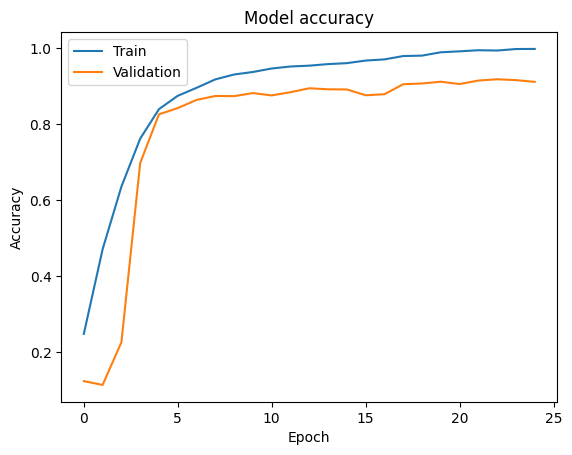

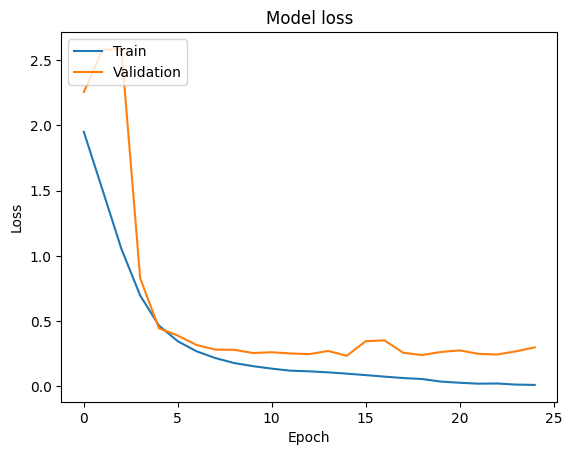

In [16]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()


102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
accuracy_score : 88.11%


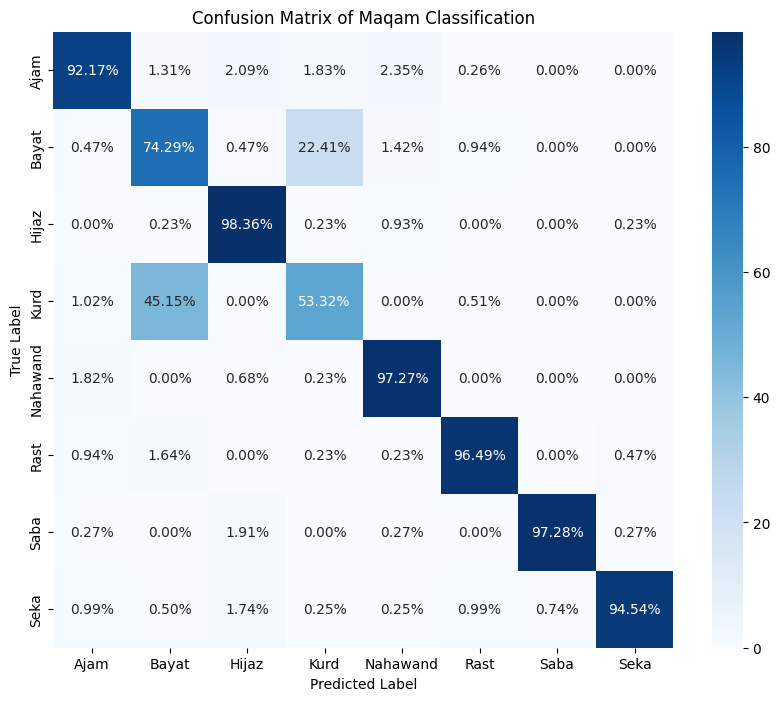

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

# Assuming model is already trained and X_test, y_test are defined
# Generate predictions for the test data
y_pred = np.argmax(model.predict(X_test), axis=1)

# Define class labels
class_labels = ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']

# Create the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

conf_matrix = conf_matrix / conf_matrix.sum(axis=1, keepdims=True) * 100

print(f'accuracy_score : {(accuracy_score(y_test, y_pred)*100):.2f}%')

annot = [[f"{value:.2f}%" for value in row] for row in conf_matrix]
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=annot, fmt='', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix of Maqam Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
